# Week 10 Assignment: Data Wrangling, Part 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

The data is from https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

You will need to look at the "Data Card" for descriptions of the columns.

In [2]:
data_df = pd.read_parquet("./spotify-tracks.parquet")

## Question 1 (1 pt) Explore and clean the data.

What are your findings with respect to the size of the dataset and missing and duplicated data?  Clean the data with respect to missing data and duplicated data, and document what you did in a markdown cell.

In [3]:
data_df.shape

(114000, 19)

In [4]:
data_df.isna().sum()

artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [5]:
data_df.duplicated().sum()

np.int64(577)

In [6]:
data_df = data_df.drop_duplicates()

In [7]:
data_df = data_df.dropna()

In [8]:
data_df.shape

(113422, 19)

In [9]:
data_df.isna().sum()

artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [10]:
data_df.duplicated().sum()

np.int64(0)

I examined missing values using .isna().sum(). I looked for duplicated observations using .duplicated().sum(). To clean the dataset, I removed duplicate rows using .drop_duplicates(). I also removed empty rows using .dropna(). Together, I removed 588 rows. 

## Question 2 (1 pt). The .str accessor
1. Create a column called `track_name_length` containing the number of characters in each track name.  It should have a pandas datatype of `Int64`.
1. Create another column `contains_love` that contains booleans identifying whether the word "love" appears in the track name.  Be careful about casing, as we want a case-insensitive indication.
1. In a markdown cell, answer:
    1. How many track names contain the word "love"?
    1. What is the longest track name in the dataset? 

In [11]:
data_df["track_name_length"] = data_df["track_name"].str.len().astype("Int64")

In [12]:
data_df["contains_love"] = data_df["track_name"].str.contains("love", case=False, na=False)

In [13]:
data_df["contains_love"].sum()

np.int64(2781)

In [14]:
data_df["track_name_length"].max()

np.int64(511)

In [15]:
data_df.loc[data_df["track_name_length"].idxmax(), "track_name"]

'Fascinados (feat. Joan Manuel Serrat, Leiva, Vetusta Morla, Iván Ferreiro, Loquillo, Zahara, Dani Martin, Albert Pla, Mikel (Izal), Noni (Lori Meyers), Santi Balmes, Xoel López, Anni B Sweet, Jeanette, Carlos Sadness, Nina (Morgan), Juan Alberto (Niños Mutantes), Miri Ros, Javiera Mena, Jorge Martí (La Habitación Roja), Rafa Val (Viva Suecia), Marc (Dorian), Alondra Bentley, Abraham Boba, Carlangas (Novedades Carminha), La Bien Querida, Martí Perarnau IV (Mucho), Nita (Fuel Fandango) & Shuarma (Elefantes))'

In [16]:
data_df[["track_name", "track_name_length", "contains_love"]].head()

,track_name,track_name_length,contains_love
track_id,,,
5SuOikwiRyPMVoIQDJUgSV,Comedy,6,False
4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,16,False
1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,14,False
6lfxq3CG4xtTiEg7opyCyx,Can't Help Falling In Love,26,True
5vjLSffimiIP26QG5WcN2K,Hold On,7,False


2781 tracks contain the word "love".
The longest track name in the data set is'Fascinados (feat. Joan Manuel Serrat, Leiva, Vetusta Morla, Iván Ferreiro, Loquillo, Zahara, Dani Martin, Albert Pla, Mikel (Izal), Noni (Lori Meyers), Santi Balmes, Xoel López, Anni B Sweet, Jeanette, Carlos Sadness, Nina (Morgan), Juan Alberto (Niños Mutantes), Miri Ros, Javiera Mena, Jorge Martí (La Habitación Roja), Rafa Val (Viva Suecia), Marc (Dorian), Alondra Bentley, Abraham Boba, Carlangas (Novedades Carminha), La Bien Querida, Martí Perarnau IV (Mucho), Nita (Fuel Fandango) & Shuarma (Elefantes))'

## Question 3 (1 pt).  `map() and apply()`
1.  Consult the Data Card and find the interetation of the value in the `mode` column.  Use `.map()` to convert the integer values into something more interpetable.
2.  Create a custom function that categorizes tempo, such that:
    * Less than 90 -> "Slow"
    * 90 - 120 -> "Moderate"
    * Higher than 120 -> "Fast"
    
    Apply the function and store the result in an `tempo_category` column.
1. In a markdown cell, answer:
    1. How many tracks in each tempo category?
    1. Which tempo category contains the most titles? 

In [17]:
data_df["mode"].value_counts()

mode
1    72327
0    41095
Name: count, dtype: int64

In [18]:
mode_dict = {
    0: "Minor",
    1: "Major"
}

In [19]:
data_df["mode"] = data_df["mode"].map(mode_dict)

In [20]:
def categorize_tempo(tempo):
    if tempo < 90:
        return "Slow"
    elif tempo <= 120:
        return "Moderate"
    else:
        return "Fast"

In [21]:
data_df["tempo_category"] = data_df["tempo"].apply(categorize_tempo)

In [22]:
data_df["tempo_category"].value_counts()

tempo_category
Fast        60382
Moderate    36788
Slow        16252
Name: count, dtype: int64

There are 60382 fast songs, 36788 moderate songs, and 16252 slow songs.
Fast songs contain the most titles.

## Question 4 (1 pt)
1. Using the `.apply()` method, create a new column called `party_category` according to the following rules:
  * If the `danceability` is `0.6` or higher and the `energy` is `0.7` or higher, the category is `"Party Time"`
  * If both the `danceability` and the `energy` is `0.25` or lower, the catgory is `"Chill"`.
  * Everything else is `"Vibe"`
2. Display the `.value_counts()` of the `party_category`

In [23]:
def categorize_party(row):
    if row["danceability"] >= 0.6 and row["energy"] >= 0.7:
        return "Party Time"
    elif row["danceability"] <= 0.25 and row["energy"] <= 0.25:
        return "Chill"
    else:
        return "Vibe"

In [24]:
data_df["party_category"] = data_df.apply(categorize_party, axis=1)

In [25]:
data_df["party_category"].value_counts()

party_category
Vibe          86171
Party Time    25048
Chill          2203
Name: count, dtype: int64

## Question 5 (1 pt). `where()` or `mask()`
1. Create a column called `duration_minutes` that represents the duration in minutes.  To convert from ms (milliseconds) to minutes, divide by 1000 and then by 60.
1. Create a column called `duration_minutes_capped` in which all `duration_minutes` greater than `10` are replaced with `10`.
1. Create a histogram of `duration_minutes_capped`. (A pandas or matplotlib plot is fine.)  
1. In a markdown cell, explain what `where()` and `mask()` do and how they are different from each other.

In [26]:
data_df["duration_minutes"] = data_df["duration_ms"] / 1000 / 60

In [27]:
data_df["duration_minutes_capped"] = data_df["duration_minutes"].where(data_df["duration_minutes"] <= 10, 10)

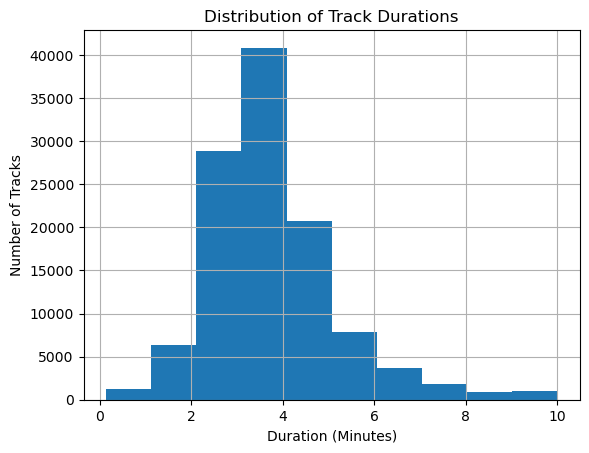

In [28]:
data_df["duration_minutes_capped"].hist()
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Tracks")
plt.title("Distribution of Track Durations")
plt.show()

The where() method keeps values that meet a specified condition and replaces values that don't meet the condition with another value. The mask() method replaces values that meet the specified condition while keeping values that don't meet it. 